# Pipeline Completa de Ciência de Dados — Classificação da Qualidade do Sono
**Dataset:** `synthetic_coffee_health_10000` (10.000 registros × 16 colunas)

**Objetivo:** analisar a tabela e construir um modelo de Machine Learning para classificar e predizer a variável-alvo `Sleep_Quality` (Poor / Fair / Good / Excellent).

**Ferramentas:** Python, pandas, scikit-learn, matplotlib, seaborn.

**Etapas:**
1. Carga e inspeção dos dados
2. Limpeza e tratamento
3. Análise Exploratória (EDA) — incluindo detecção de *vazamento de dados*
4. Pré-processamento com `Pipeline` + `ColumnTransformer`
5. Modelagem em dois cenários (com e sem a variável vazada)
6. Otimização de hiperparâmetros com `GridSearchCV` + validação cruzada
7. Avaliação final, importância de variáveis e conclusões

## 1. Carga e inspeção dos dados

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from google.colab import drive
drive.mount('/content/drive')

sns.set_theme(style='whitegrid', font_scale=0.95)
pd.set_option('display.max_columns', None)

CSV = '/content/drive/MyDrive/ESTUDANDO DE FORMA ORGANIZADA/checkpoint LV 1/synthetic_coffee_health_10000(in).csv'
df = pd.read_csv(CSV)
print('Dimensões:', df.shape)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensões: (10000, 16)


,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


In [33]:
df.columns = [
    'ID',
    'Idade',
    'Gênero',
    'País',
    'Consumo_de_Café',
    'Cafeína_mg',
    'Horas_de_Sono',
    'Qualidade_do_Sono',
    'IMC',
    'Frequência_Cardíaca',
    'Nível_de_Estresse',
    'Horas_de_Atividade_Física',
    'Problemas_de_Saúde',
    'Ocupação',
    'Tabagismo',
    'Consumo_de_Álcool'
]

df.head()

,ID,Idade,Gênero,País,Consumo_de_Café,Cafeína_mg,Horas_de_Sono,Qualidade_do_Sono,IMC,Frequência_Cardíaca,Nível_de_Estresse,Horas_de_Atividade_Física,Problemas_de_Saúde,Ocupação,Tabagismo,Consumo_de_Álcool
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         10000 non-null  int64  
 1   Idade                      10000 non-null  int64  
 2   Gênero                     10000 non-null  object 
 3   País                       10000 non-null  object 
 4   Consumo_de_Café            10000 non-null  float64
 5   Cafeína_mg                 10000 non-null  float64
 6   Horas_de_Sono              10000 non-null  float64
 7   Qualidade_do_Sono          10000 non-null  object 
 8   IMC                        10000 non-null  float64
 9   Frequência_Cardíaca        10000 non-null  int64  
 10  Nível_de_Estresse          10000 non-null  object 
 11  Horas_de_Atividade_Física  10000 non-null  float64
 12  Problemas_de_Saúde         4059 non-null   object 
 13  Ocupação                   10000 non-null  obje

In [35]:
# Estatísticas descritivas das variáveis numéricas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,10000.0,5000.50,2886.90,1.0,2500.75,5000.5,7500.25,10000.0
Idade,10000.0,34.95,11.16,18.0,26.00,34.0,43.00,80.0
Consumo_de_Café,10000.0,2.51,1.45,0.0,1.50,2.5,3.50,8.2
Cafeína_mg,10000.0,238.41,137.75,0.0,138.75,235.4,332.02,780.3
Horas_de_Sono,10000.0,6.64,1.22,3.0,5.80,6.6,7.50,10.0
IMC,10000.0,23.99,3.91,15.0,21.30,24.0,26.60,38.2
Frequência_Cardíaca,10000.0,70.62,9.82,50.0,64.00,71.0,77.00,109.0
Horas_de_Atividade_Física,10000.0,7.49,4.32,0.0,3.70,7.5,11.20,15.0
Tabagismo,10000.0,0.20,0.40,0.0,0.00,0.0,0.00,1.0
Consumo_de_Álcool,10000.0,0.30,0.46,0.0,0.00,0.0,1.00,1.0


In [36]:
# Valores ausentes e duplicatas
print('Nulos por coluna:')
print(df.isnull().sum())
print('\nDuplicatas:', df.duplicated().sum())

Nulos por coluna:
ID                              0
Idade                           0
Gênero                          0
País                            0
Consumo_de_Café                 0
Cafeína_mg                      0
Horas_de_Sono                   0
Qualidade_do_Sono               0
IMC                             0
Frequência_Cardíaca             0
Nível_de_Estresse               0
Horas_de_Atividade_Física       0
Problemas_de_Saúde           5941
Ocupação                        0
Tabagismo                       0
Consumo_de_Álcool               0
dtype: int64

Duplicatas: 0


In [37]:
# Distribuição da variável-alvo (classes desbalanceadas)
df['Qualidade_do_Sono'].value_counts()

,count
Qualidade_do_Sono,
Good,5637
Fair,2050
Excellent,1352
Poor,961


## 2. Limpeza e tratamento

Os 5.941 nulos em `Health_Issues` **não são dados faltantes**: representam ausência de problema de saúde. Imputamos a categoria explícita `'None'`. A coluna `ID` é apenas um identificador sequencial e será excluída da modelagem.

In [38]:
df['Problemas_de_Saúde'] = df['Problemas_de_Saúde'].fillna('None')
df['Problemas_de_Saúde'].value_counts()

,count
Problemas_de_Saúde,
None,5941
Mild,3579
Moderate,463
Severe,17


In [39]:
df.columns

Index(['ID', 'Idade', 'Gênero', 'País', 'Consumo_de_Café', 'Cafeína_mg',
       'Horas_de_Sono', 'Qualidade_do_Sono', 'IMC', 'Frequência_Cardíaca',
       'Nível_de_Estresse', 'Horas_de_Atividade_Física', 'Problemas_de_Saúde',
       'Ocupação', 'Tabagismo', 'Consumo_de_Álcool'],
      dtype='object')

## 3. Análise Exploratória (EDA)

### 3.1 Distribuição do alvo e das variáveis numéricas

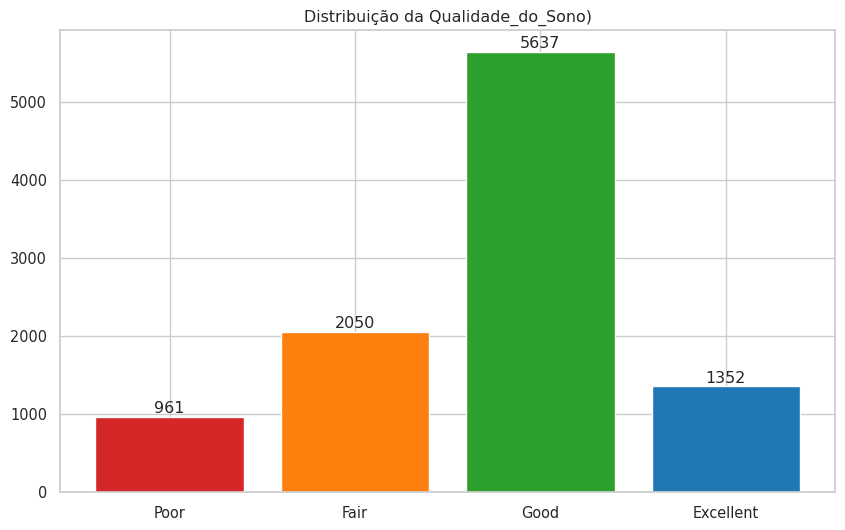

In [40]:
order = ['Poor', 'Fair', 'Good', 'Excellent']
pal = {'Poor': '#d62728', 'Fair': '#ff7f0e', 'Good': '#2ca02c', 'Excellent': '#1f77b4'}

counts = df['Qualidade_do_Sono'].value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(counts.index, counts.values, color=[pal[c] for c in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v + 50, str(v), ha='center')
ax.set_title('Distribuição da Qualidade_do_Sono)')
plt.show()

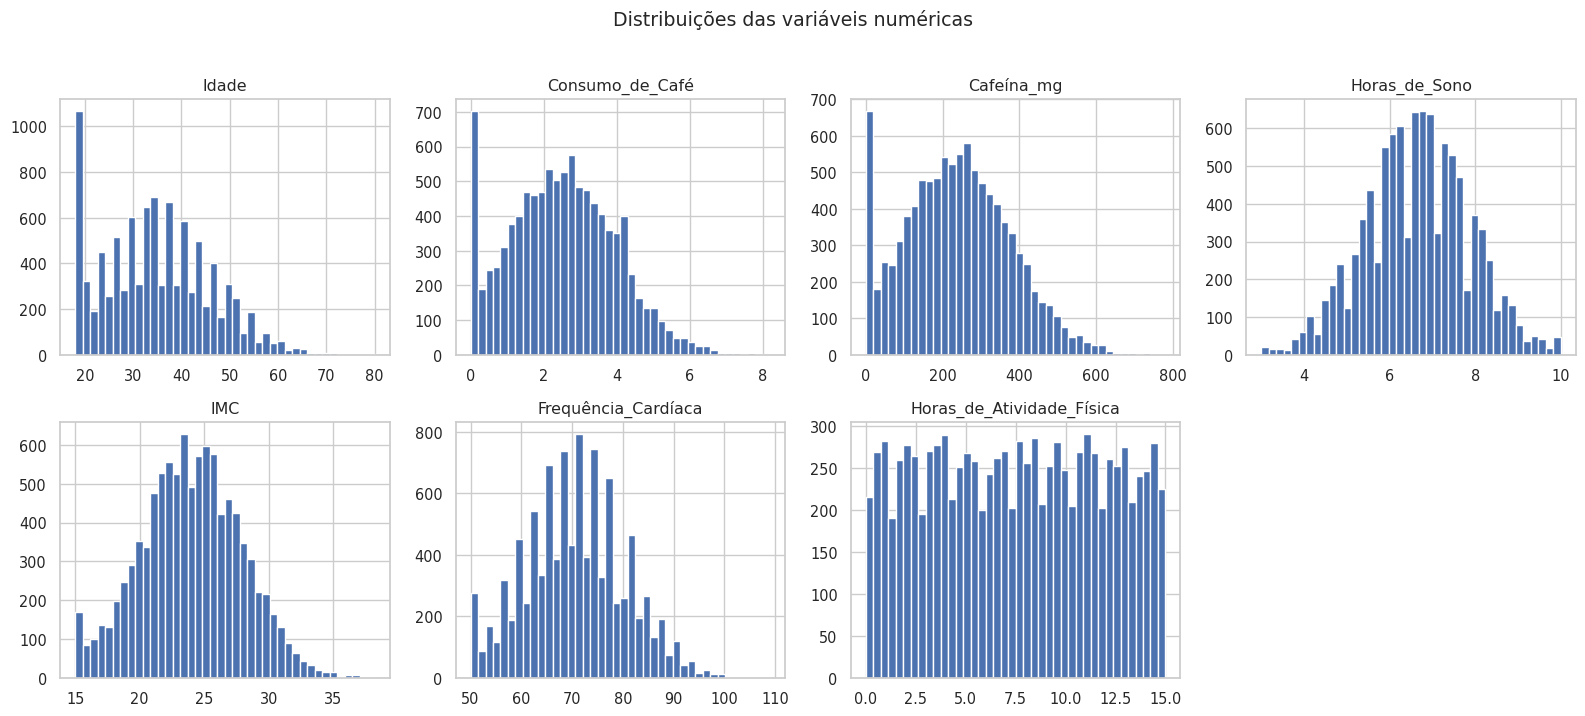

In [41]:
num_cols = ['Idade', 'Consumo_de_Café', 'Cafeína_mg', 'Horas_de_Sono',
            'IMC', 'Frequência_Cardíaca', 'Horas_de_Atividade_Física']
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, num_cols):
    ax.hist(df[c], bins=40, color='#4c72b0', edgecolor='white')
    ax.set_title(c)
axes.flat[-1].axis('off')
plt.suptitle('Distribuições das variáveis numéricas', y=1.02)
plt.tight_layout()
plt.show()

In [42]:
px.histogram(df, x="Horas_de_Sono", text_auto= True,)

### 3.2 Achado central: vazamento de dados (*data leakage*)

Cruzando `Horas_de_Sono` com o alvo, a separação é **perfeita e determinística** — o rótulo foi gerado a partir de faixas exatas de horas de sono:

| Classe | Faixa de Sleep_Hours |
|---|---|
| Poor | 3,0 – 5,0 h |
| Fair | 5,0 – 6,0 h |
| Good | 6,0 – 8,0 h |
| Excellent | 8,0 – 10,0 h |



In [43]:
df.groupby('Qualidade_do_Sono')['Horas_de_Sono'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Qualidade_do_Sono,,,,,,,,
Excellent,1352.0,8.59,0.50,8.0,8.2,8.5,8.8,10.0
Fair,2050.0,5.58,0.28,5.0,5.4,5.6,5.8,6.0
Good,5637.0,6.92,0.55,6.0,6.5,6.9,7.4,8.0
Poor,961.0,4.45,0.46,3.0,4.2,4.6,4.8,5.0


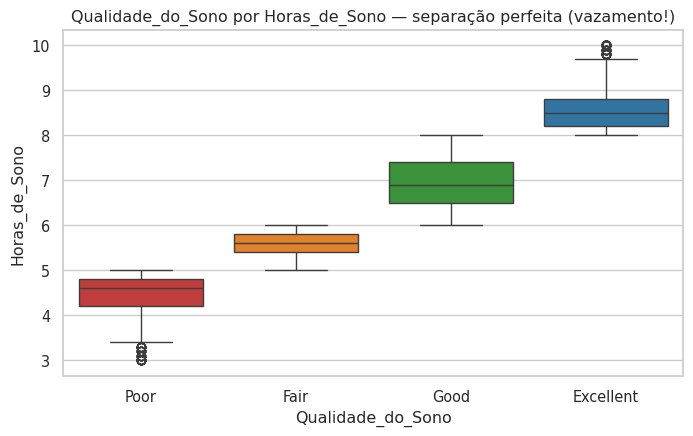

In [44]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x='Qualidade_do_Sono', y='Horas_de_Sono', order=order,
            hue='Qualidade_do_Sono', palette=pal, legend=False, ax=ax)
ax.set_title('Qualidade_do_Sono por Horas_de_Sono — separação perfeita (vazamento!)')
plt.show()

`Stress_Level` também é determinístico em relação ao alvo: **High → 100% Poor**, **Medium → 100% Fair**, **Low → 80,7% Good / 19,3% Excellent**.

In [46]:
pd.crosstab(df['Nível_de_Estresse'], df['Qualidade_do_Sono'], normalize='index').round(3)

Qualidade_do_Sono,Excellent,Fair,Good,Poor
Nível_de_Estresse,,,,
High,0.000,0.0,0.000,1.0
Low,0.193,0.0,0.807,0.0
Medium,0.000,1.0,0.000,0.0


### 3.3 Correlações e relações com o alvo

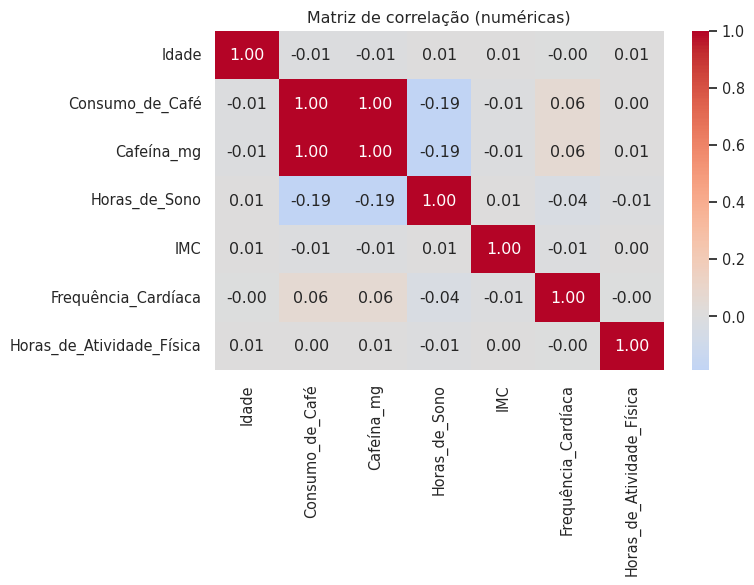

In [47]:
corr = df[num_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlação (numéricas)')
plt.tight_layout()
plt.show()
# Única correlação comportamental relevante: Caffeine_mg x Sleep_Hours = -0.19

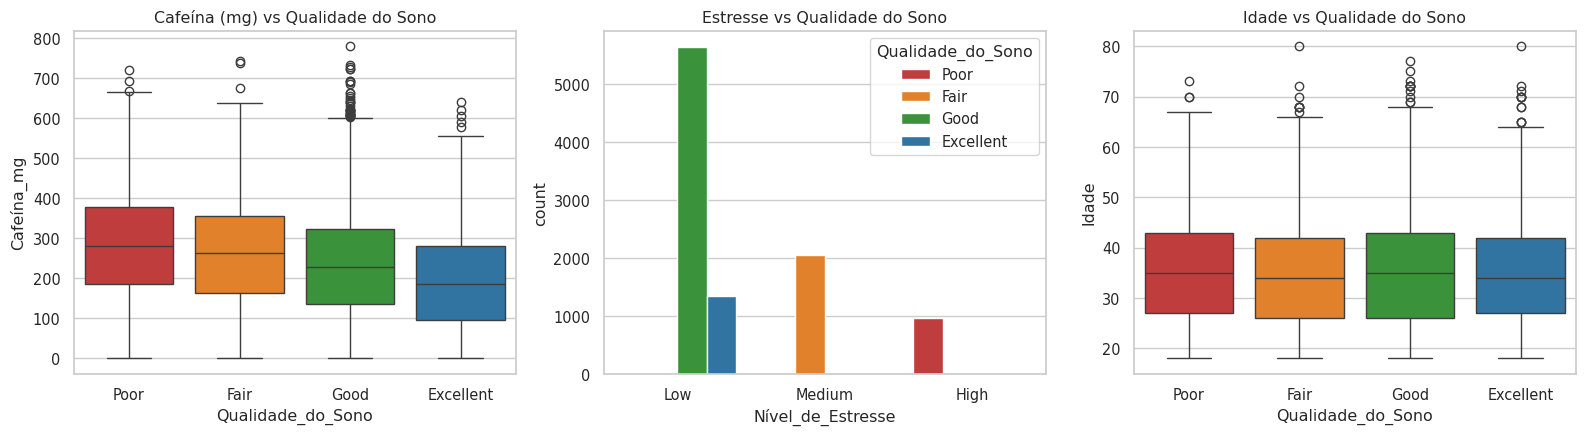

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x='Qualidade_do_Sono', y='Cafeína_mg', order=order,
            hue='Qualidade_do_Sono', palette=pal, legend=False, ax=axes[0])
axes[0].set_title('Cafeína (mg) vs Qualidade do Sono')
sns.countplot(data=df, x='Nível_de_Estresse', hue='Qualidade_do_Sono', hue_order=order,
              palette=pal, order=['Low', 'Medium', 'High'], ax=axes[1])
axes[1].set_title('Estresse vs Qualidade do Sono')
sns.boxplot(data=df, x='Qualidade_do_Sono', y='Idade', order=order,
            hue='Qualidade_do_Sono', palette=pal, legend=False, ax=axes[2])
axes[2].set_title('Idade vs Qualidade do Sono')
plt.tight_layout()
plt.show()

## 4. Pré-processamento

Todo o pré-processamento é encapsulado em `Pipeline` + `ColumnTransformer`, de modo que escalonamento e codificação sejam ajustados **apenas no treino** (e refeitos dentro de cada fold da validação cruzada) — boa prática que evita vazamento treino/teste.

- **Numéricas** → `StandardScaler`
- **Ordinais** (`Problemas_de_Saúde`, `Nível_de_Estresse`) → `OrdinalEncoder` com ordem natural
- **Nominais** (`Gênero`, `País`, `Ocupação`) → `OneHotEncoder`

In [51]:
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     GridSearchCV, StratifiedKFold)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)

y = df['Qualidade_do_Sono']
cat_cols = ['Gênero', 'País', 'Ocupação']
ord_cols = ['Problemas_de_Saúde', 'Nível_de_Estresse']
num_full = ['Idade', 'Consumo_de_Café', 'Cafeína_mg', 'Horas_de_Sono', 'IMC',
            'Frequência_Cardíaca', 'Horas_de_Atividade_Física', 'Tabagismo', 'Consumo_de_Álcool']
num_sem_sleep = [c for c in num_full if c != 'Horas_de_Sono']

def make_preprocessor(num_cols):
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('ord', OrdinalEncoder(categories=[['None', 'Mild', 'Moderate', 'Severe'],
                                           ['Low', 'Medium', 'High']]), ord_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Pré-processador definido.')

Pré-processador definido.


In [52]:
df

,ID,Idade,Gênero,País,Consumo_de_Café,Cafeína_mg,Horas_de_Sono,Qualidade_do_Sono,IMC,Frequência_Cardíaca,Nível_de_Estresse,Horas_de_Atividade_Física,Problemas_de_Saúde,Ocupação,Tabagismo,Consumo_de_Álcool
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,None,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,None,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,50,Female,Japan,2.1,199.8,6.0,Fair,30.5,50,Medium,10.1,Moderate,Healthcare,0,1
9996,9997,18,Female,UK,3.4,319.2,5.8,Fair,19.1,71,Medium,11.6,Mild,Service,0,0
9997,9998,26,Male,China,1.6,153.4,7.1,Good,25.1,66,Low,13.7,None,Student,1,1
9998,9999,40,Female,Finland,3.4,327.1,7.0,Good,19.3,80,Low,0.1,None,Student,0,0


## 5. Modelagem — dois cenários

- **Cenário A (com `Sleep_Hours`)**: demonstra o vazamento — qualquer modelo atinge ~99%.
- **Cenário B (sem `Sleep_Hours`)**: cenário realista — predição da qualidade do sono a partir de estilo de vida e saúde.

In [53]:
modelos = {
    'LogisticRegression': LogisticRegression(max_iter=2000),
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42),
}

baseline = {}
for cenario, num_cols in [('A (com Sleep_Hours)', num_full),
                          ('B (sem Sleep_Hours)', num_sem_sleep)]:
    X = df[num_cols + ord_cols + cat_cols]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                              stratify=y, random_state=42)
    for nome, mdl in modelos.items():
        pipe = Pipeline([('pre', make_preprocessor(num_cols)), ('clf', mdl)])
        pipe.fit(X_tr, y_tr)
        pred = pipe.predict(X_te)
        acc = accuracy_score(y_te, pred)
        f1 = f1_score(y_te, pred, average='macro')
        baseline[(cenario, nome)] = f1
        print(f'Cenário {cenario} | {nome:22s} acc = {acc:.4f} | f1_macro = {f1:.4f}')

Cenário A (com Sleep_Hours) | LogisticRegression     acc = 0.9890 | f1_macro = 0.9873
Cenário A (com Sleep_Hours) | RandomForest           acc = 0.9905 | f1_macro = 0.9890
Cenário A (com Sleep_Hours) | HistGradientBoosting   acc = 0.9910 | f1_macro = 0.9897
Cenário B (sem Sleep_Hours) | LogisticRegression     acc = 0.8650 | f1_macro = 0.7233
Cenário B (sem Sleep_Hours) | RandomForest           acc = 0.8650 | f1_macro = 0.7251
Cenário B (sem Sleep_Hours) | HistGradientBoosting   acc = 0.8485 | f1_macro = 0.7305


**Leitura dos resultados:** no cenário A todos os modelos beiram 99% — confirmação de que `Sleep_Hours` "entrega" o rótulo. Todo o restante do trabalho usa o **cenário B**.

## 6. Otimização de hiperparâmetros — `GridSearchCV` + validação cruzada

- Métrica de seleção: **f1_macro** (adequada ao desbalanceamento de classes).
- CV: `StratifiedKFold(5)`.
- O prefixo `clf__` nas grades direciona os parâmetros à etapa do `Pipeline`, garantindo que o pré-processamento seja reajustado dentro de cada fold.
- Usamos `HistGradientBoostingClassifier` (variante *histogram-based* do Gradient Boosting): mesmo princípio, ordens de magnitude mais rápido em buscas em grade.

In [54]:
X = df[num_sem_sleep + ord_cols + cat_cols]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          stratify=y, random_state=42)
pre = make_preprocessor(num_sem_sleep)

buscas = {
    'LogisticRegression': (
        LogisticRegression(max_iter=3000),
        {'clf__C': [0.01, 0.1, 1, 10, 100],
         'clf__class_weight': [None, 'balanced']},
    ),
    'RandomForest': (
        RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=2),
        {'clf__max_depth': [20, None],
         'clf__min_samples_leaf': [1, 10],
         'clf__class_weight': [None, 'balanced']},
    ),
    'HistGradientBoosting': (
        HistGradientBoostingClassifier(random_state=42),
        {'clf__learning_rate': [0.05, 0.1],
         'clf__max_iter': [100, 200],
         'clf__max_depth': [3, None]},
    ),
}

resultados = {}
for nome, (mdl, grade) in buscas.items():
    pipe = Pipeline([('pre', pre), ('clf', mdl)])
    gs = GridSearchCV(pipe, grade, cv=cv, scoring='f1_macro', n_jobs=-1, refit=True)
    gs.fit(X_tr, y_tr)
    pred = gs.predict(X_te)
    resultados[nome] = gs
    print(f'\n{nome} — {len(gs.cv_results_["params"])} combinações x 5 folds')
    print('Melhores parâmetros:', gs.best_params_)
    print(f'CV f1_macro = {gs.best_score_:.4f} | '
          f'Teste: acc = {accuracy_score(y_te, pred):.4f}, '
          f'f1_macro = {f1_score(y_te, pred, average="macro"):.4f}')


LogisticRegression — 10 combinações x 5 folds
Melhores parâmetros: {'clf__C': 1, 'clf__class_weight': 'balanced'}
CV f1_macro = 0.7442 | Teste: acc = 0.6775, f1_macro = 0.7425

RandomForest — 8 combinações x 5 folds
Melhores parâmetros: {'clf__class_weight': 'balanced', 'clf__max_depth': 20, 'clf__min_samples_leaf': 10}
CV f1_macro = 0.7667 | Teste: acc = 0.8045, f1_macro = 0.7694

HistGradientBoosting — 8 combinações x 5 folds
Melhores parâmetros: {'clf__learning_rate': 0.1, 'clf__max_depth': None, 'clf__max_iter': 200}
CV f1_macro = 0.7420 | Teste: acc = 0.8440, f1_macro = 0.7361


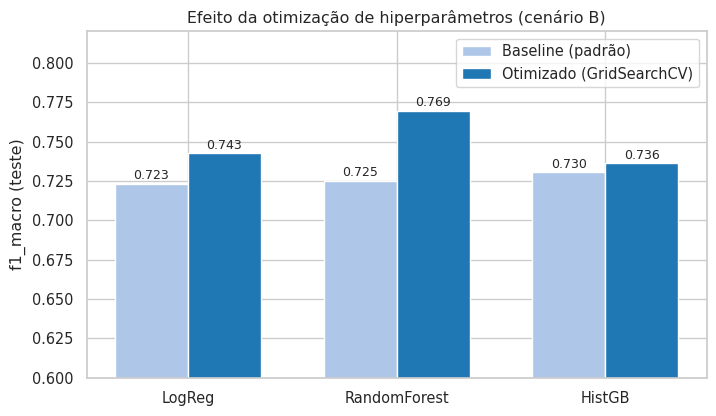

In [55]:
# Comparação baseline (parâmetros padrão) vs otimizado (GridSearchCV)
nomes = list(buscas.keys())
f1_base = [baseline[('B (sem Sleep_Hours)', n)] for n in nomes]
f1_opt = [f1_score(y_te, resultados[n].predict(X_te), average='macro') for n in nomes]

x = np.arange(len(nomes)); w = 0.35
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w/2, f1_base, w, label='Baseline (padrão)', color='#aec7e8')
ax.bar(x + w/2, f1_opt, w, label='Otimizado (GridSearchCV)', color='#1f77b4')
ax.set_xticks(x); ax.set_xticklabels(['LogReg', 'RandomForest', 'HistGB'])
ax.set_ylabel('f1_macro (teste)'); ax.set_ylim(0.6, 0.82)
ax.set_title('Efeito da otimização de hiperparâmetros (cenário B)')
ax.legend()
for i in range(len(nomes)):
    ax.text(i - w/2, f1_base[i] + 0.003, f'{f1_base[i]:.3f}', ha='center', fontsize=9)
    ax.text(i + w/2, f1_opt[i] + 0.003, f'{f1_opt[i]:.3f}', ha='center', fontsize=9)
plt.show()

## 7. Avaliação final do melhor modelo

In [56]:
melhor = max(resultados, key=lambda n: f1_score(
    y_te, resultados[n].predict(X_te), average='macro'))
pred = resultados[melhor].predict(X_te)
print(f'=== MODELO FINAL: {melhor} ===')
print('Parâmetros:', resultados[melhor].best_params_)
print()
print(classification_report(y_te, pred, zero_division=0))

=== MODELO FINAL: RandomForest ===
Parâmetros: {'clf__class_weight': 'balanced', 'clf__max_depth': 20, 'clf__min_samples_leaf': 10}

              precision    recall  f1-score   support

   Excellent       0.26      0.24      0.25       270
        Fair       1.00      1.00      1.00       410
        Good       0.82      0.84      0.83      1128
        Poor       1.00      1.00      1.00       192

    accuracy                           0.80      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.80      0.80      0.80      2000



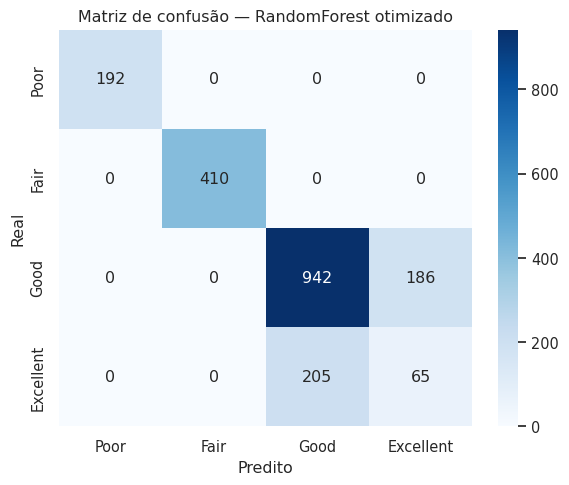

In [64]:
cm = confusion_matrix(y_te, pred, labels=order)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=order, yticklabels=order)
plt.xlabel('Predito'); plt.ylabel('Real')
plt.title(f'Matriz de confusão — {melhor} otimizado')
plt.tight_layout()
plt.show()

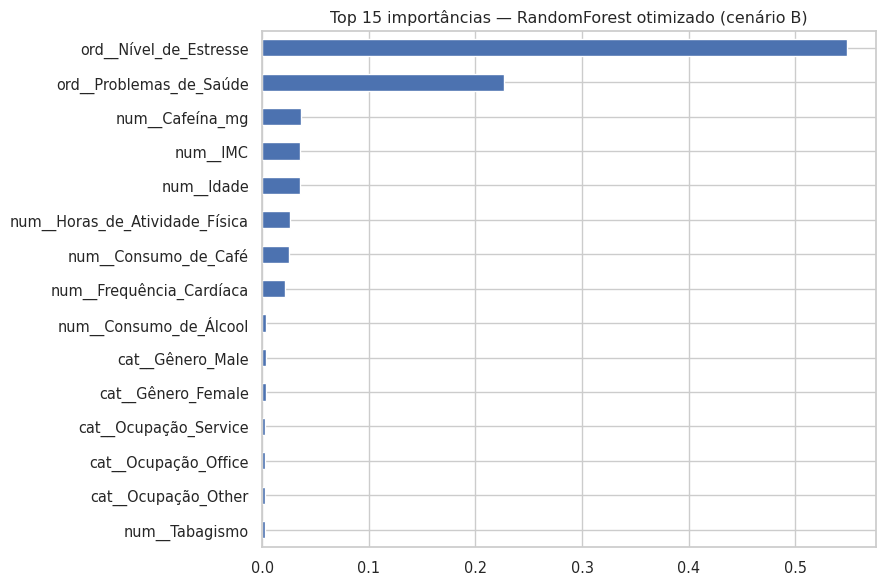

In [65]:
# Importância de variáveis (RandomForest otimizado)
rf_best = resultados['RandomForest'].best_estimator_
nomes_feat = rf_best.named_steps['pre'].get_feature_names_out()
imp = pd.Series(rf_best.named_steps['clf'].feature_importances_,
                index=nomes_feat).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6))
imp[::-1].plot(kind='barh', color='#4c72b0')
plt.title('Top 15 importâncias — RandomForest otimizado (cenário B)')
plt.tight_layout()
plt.show()

In [66]:
# Persistência do modelo final para uso em produção
import joblib
joblib.dump(resultados[melhor].best_estimator_, 'modelo_sleep_quality.joblib')
print('Modelo salvo em modelo_sleep_quality.joblib')

# Exemplo de predição em novos dados:
exemplo = X_te.iloc[[0]]
print('\nExemplo de entrada:')
display(exemplo)
print('Predição:', resultados[melhor].predict(exemplo)[0])

Modelo salvo em modelo_sleep_quality.joblib

Exemplo de entrada:


,Idade,Consumo_de_Café,Cafeína_mg,IMC,Frequência_Cardíaca,Horas_de_Atividade_Física,Tabagismo,Consumo_de_Álcool,Problemas_de_Saúde,Nível_de_Estresse,Gênero,País,Ocupação
4695,32,5.6,531.7,19.2,63,4.6,0,1,Mild,Medium,Male,France,Healthcare


Predição: Fair


## 8. Conclusões

1. **O dataset é sintético e gerado por regras determinísticas**: `Sleep_Quality` é função direta de `Sleep_Hours` (faixas exatas), e `Stress_Level` mapeia perfeitamente as classes Poor e Fair.
2. **Com `Sleep_Hours`, qualquer modelo atinge ~99%** — um caso didático de *target leakage*. Reportar esse número como desempenho real seria um erro grave de ciência de dados.
3. **No cenário realista (sem `Sleep_Hours`)**, o melhor modelo foi o **Random Forest otimizado** (`class_weight='balanced'`, `min_samples_leaf=10`, `max_depth=20`), com **f1_macro ≈ 0,77** — ganho de ~0,05 sobre o baseline. Poor e Fair são previstos com 100% (via `Stress_Level`); o recall de Excellent subiu de 0% para ~24%.
4. **O teto de ~80–86% de acurácia é estrutural**, não falha de modelagem: Good e Excellent diferem apenas pelas horas de sono, removidas por vazamento. Nenhuma otimização adicional romperá esse limite.
5. **Recomendações para um projeto real**: coletar variáveis adicionais (higiene do sono, horários, uso de telas, qualidade subjetiva), validar com dados não sintéticos e monitorar o modelo em produção.

**Boas práticas aplicadas:** tratamento semântico de nulos, detecção de vazamento, `Pipeline`/`ColumnTransformer` (sem vazamento treino/teste), split estratificado, validação cruzada estratificada, métrica adequada ao desbalanceamento (f1_macro), comparação de múltiplos algoritmos, otimização de hiperparâmetros, análise de erros e persistência do modelo.